# Advecting Every Polarimetric Variable Through One Motion Field

**`radar-palette` · ARM BNF C-SAPR2 · 8 August 2026**

---

A companion to
[Radar_Volume_Advection_Interpolation.ipynb](Radar_Volume_Advection_Interpolation.ipynb),
which builds advection morphing from first principles on reflectivity. This one uses the
packaged operator in [`radar-palette`](https://github.com/DIGR-Legacy/radar-palette) and
addresses the question that follows immediately: **what about the other variables?**

Reflectivity is a tracer. The polarimetric variables are not:

| Variable | Why it cannot drive the flow |
| --- | --- |
| $Z_{DR}$ | a shape measure, not a quantity that is conserved as echo moves |
| $\rho_{HV}$ | closer to a quality flag than a field |
| $V_r$ | signed, and folded at the Nyquist interval |

So estimating optical flow four times, once per variable, would track the wrong thing
three times out of four. Motion is a property of the **scene**: estimate it once from
$Z_H$ and apply that displacement to everything. That is what `carry_fields` does.

## 1. Data

Two consecutive C-SAPR2 volumes, 480 s apart, from ARM Live. Set `ARM_USERNAME` and
`ARM_TOKEN` in your environment; an existing local copy is used if present.

In [1]:
# radar-palette is not on PyPI yet:
#   pip install git+https://github.com/DIGR-Legacy/radar-palette.git

import os
import glob
import urllib.request

import numpy as np
import pyart

DATASTREAM = "bnfcsapr2cfrS3.a1"
VOLUMES = ["bnfcsapr2cfrS3.a1.20260808.175537.nc",
           "bnfcsapr2cfrS3.a1.20260808.180337.nc"]

# Use a local copy if one exists, otherwise stage from ARM Live (~730 MB per volume).
LOCAL = "/Users/scollis/data/REAL/bnf_advection/case_20260808_1755"
DATADIR = LOCAL if os.path.isdir(LOCAL) else "data"
os.makedirs(DATADIR, exist_ok=True)

SAVE = "https://adc.arm.gov/armlive/livedata/saveData?user={u}:{t}&file={f}"
for name in VOLUMES:
    path = os.path.join(DATADIR, name)
    if os.path.exists(path):
        continue
    user, token = os.environ.get("ARM_USERNAME"), os.environ.get("ARM_TOKEN")
    if not (user and token):
        raise RuntimeError("set ARM_USERNAME and ARM_TOKEN, or point DATADIR at local files")
    urllib.request.urlretrieve(SAVE.format(u=user, t=token, f=name), path)

earlier = pyart.io.read(os.path.join(DATADIR, VOLUMES[0]))
later = pyart.io.read(os.path.join(DATADIR, VOLUMES[1]))

FIELDS = ["reflectivity", "mean_doppler_velocity",
          "differential_reflectivity", "copol_correlation_coeff"]
for name, radar in (("earlier", earlier), ("later", later)):
    print(f"{name}: {pyart.util.datetime_from_radar(radar):%H:%M:%S}  "
          f"{radar.nsweeps} sweeps, {radar.nrays} rays, {radar.ngates} gates")
print("fields present:", all(f in earlier.fields for f in FIELDS))

earlier: 17:55:37  15 sweeps, 13953 rays, 1050 gates
later: 18:03:37  15 sweeps, 13952 rays, 1050 gates
fields present: True


Note the ray counts. Consecutive volumes running the *same* scan strategy do not repeat
them exactly, so an operator that requires matching ray counts rejects essentially every
real pair. A real antenna also records the same azimuth twice when it dwells — not in
this pair, but in 3 of the 195 sweeps across the 13 volumes of this case — which makes a
wrap-tiled interpolation axis non-strictly-ascending. Both are handled rather than
raising.

In [2]:
print("ray counts:", earlier.nrays, later.nrays)

duplicated = 0
for radar in (earlier, later):
    for sweep in range(radar.nsweeps):
        azimuths = np.sort(radar.azimuth["data"][radar.get_slice(sweep)])
        duplicated += int(np.sum(np.diff(azimuths) == 0))
print("repeated azimuths in this pair:", duplicated, "(other volumes of this case do have them)")

ray counts: 13953 13952
repeated azimuths in this pair: 0 (other volumes of this case do have them)


## 2. One flow estimate, four variables

`carry_fields` names the variables that ride along. The tracer is `field`; everything in
`carry_fields` is warped by the *same* displacement, resampled with the same interpolant,
and blended with the same weights. Four fields cost one flow estimate and one gridding
pass, not four.

`alpha` is the fractional position between the volumes: 0 is the earlier scan, 1 the later.

In [3]:
from radar_palette.advection import advection_interpolate, volume_reference_time

midpoint = advection_interpolate(
    earlier, later,
    alpha=0.5,
    field="reflectivity",            # the tracer the motion comes from
    carry_fields=FIELDS[1:],         # warped by that same motion
)

print("reconstructed:", sorted(midpoint.fields))
print("volume time  :", f"{volume_reference_time(midpoint):%H:%M:%S}")
print("units kept   :", {f: midpoint.fields[f]["units"] for f in FIELDS})

reconstructed: ['copol_correlation_coeff', 'differential_reflectivity', 'mean_doppler_velocity', 'reflectivity']
volume time  : 18:03:07
units kept   : {'reflectivity': 'dBZ', 'mean_doppler_velocity': 'm/s', 'differential_reflectivity': 'dB', 'copol_correlation_coeff': '1'}


The reconstruction carries the interpolated acquisition time, not the earlier volume's
clock — and each variable keeps its own metadata, so a carried $Z_{DR}$ field stays dB
rather than inheriting dBZ from the tracer.

## 3. The motion field

Worth looking at directly, since everything above depends on it. Speed is quoted over
echo rather than over the whole domain.

In [4]:
from radar_palette.advection import grid_optical_flow

GRID = dict(grid_shape=(8, 241, 241),
            grid_limits=((1000., 8000.), (-120000., 120000.), (-120000., 120000.)),
            fields=["reflectivity"], weighting_function="Barnes2",
            roi_func="dist_beam", min_radius=1000.0)

grid_early = pyart.map.grid_from_radars((earlier,), **GRID)
grid_late = pyart.map.grid_from_radars((later,), **GRID)
north, east = grid_optical_flow(grid_early, grid_late, "reflectivity")

gap_s = (volume_reference_time(later) - volume_reference_time(earlier)).total_seconds()
gridded_z = np.ma.filled(grid_early.fields["reflectivity"]["data"].astype(float), np.nan)
echo = np.isfinite(gridded_z) & (gridded_z > 25)
speed = np.hypot(north, east) / gap_s

median_speed = np.nanmedian(speed[echo])
scatter = np.nanpercentile(np.abs(speed[echo] - median_speed), 50)
print(f"echo cells > 25 dBZ : {int(echo.sum())}")
print(f"median speed        : {median_speed:.2f} m/s")
print(f"displacement per gap: {median_speed * gap_s / 1e3:.2f} km")
print(f"coherence           : {median_speed / scatter:.2f}")

echo cells > 25 dBZ : 5655
median speed        : 4.97 m/s
displacement per gap: 2.38 km
coherence           : 3.95


**Coherence** — median speed divided by the median absolute deviation about it — is the
number that predicts whether a single warp field can fit the scene. It is high when the
echo translates rigidly and low when the scene is a system whose parts move differently.

Report advection skill together with this number. It is a property of the scene, not of
the operator: the same code scores far better on a small, coherently translating cell
than on a mesoscale system, and neither result says anything about the implementation.

## 4. Four panels

On native radial geometry — no gridding, no gatefilter. Py-ART's mapped-PPI path places
this radar's site about 21 km from its own coordinates, so gate positions are built
directly with the AEQD transform, with the radar as the explicit origin.

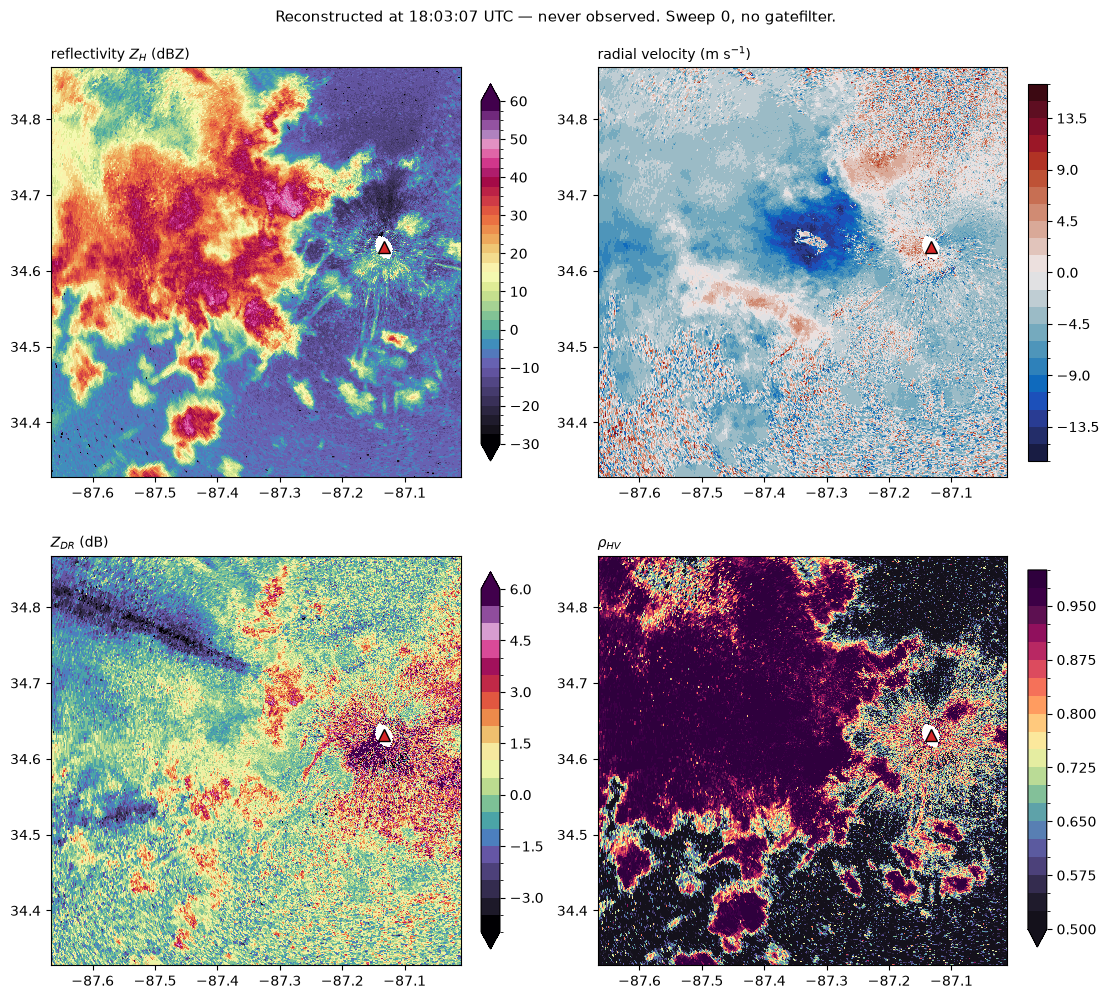

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from pyart.core import cartesian_to_geographic_aeqd

RLAT = float(earlier.latitude["data"][0])
RLON = float(earlier.longitude["data"][0])

def sweep0(radar, names):
    """Sweep-0 gate longitude, latitude and fields, on native radial geometry."""
    rays = radar.get_slice(0)
    x, y, _ = radar.get_gate_x_y_z(0)
    lon, lat = cartesian_to_geographic_aeqd(x, y, RLON, RLAT)
    values = {n: np.ma.filled(radar.fields[n]["data"].astype("float32"), np.nan)[rays]
              for n in names}
    return lon.astype("float32"), lat.astype("float32"), values

PANELS = [
    ("reflectivity", r"reflectivity $Z_H$ (dBZ)", np.arange(-30, 62, 2.5), "ChaseSpectral", "both"),
    ("mean_doppler_velocity", r"radial velocity (m s$^{-1}$)", np.arange(-16.5, 18, 1.5), "balance", "neither"),
    ("differential_reflectivity", r"$Z_{DR}$ (dB)", np.arange(-4, 6.5, 0.5), "ChaseSpectral", "both"),
    ("copol_correlation_coeff", r"$\rho_{HV}$", np.arange(0.5, 1.025, 0.025), "SpectralExtended", "min"),
]

lon, lat, values = sweep0(midpoint, FIELDS)

# A window on the convective core: at full range the scene's few-km translation is only
# a handful of pixels, and the uncorrelated noise field reads as more motion than the echo.
HALF_KM = 30.0
core = np.isfinite(values["reflectivity"]) & (values["reflectivity"] > 40)
cx = float(np.mean((lon[core] - RLON) * 111.0 * np.cos(np.deg2rad(RLAT))))
cy = float(np.mean((lat[core] - RLAT) * 111.0))
lon_c = RLON + cx / (111.0 * np.cos(np.deg2rad(RLAT)))
lat_c = RLAT + cy / 111.0
extent = [lon_c - HALF_KM / (111.0 * np.cos(np.deg2rad(RLAT))),
          lon_c + HALF_KM / (111.0 * np.cos(np.deg2rad(RLAT))),
          lat_c - HALF_KM / 111.0, lat_c + HALF_KM / 111.0]

fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
for ax, (name, label, levels, cmap, extend) in zip(axes.ravel(), PANELS):
    mesh = ax.pcolormesh(lon, lat, np.ma.masked_invalid(values[name]),
                         cmap=cmap, norm=BoundaryNorm(levels, 256), shading="nearest")
    ax.plot(RLON, RLAT, marker="^", ms=8, mfc="#d62728", mec="k", ls="none")
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_aspect(1 / np.cos(np.deg2rad(RLAT)))
    ax.set_title(label, fontsize=10, loc="left")
    fig.colorbar(mesh, ax=ax, extend=extend, fraction=0.046)
fig.suptitle(f"Reconstructed at {volume_reference_time(midpoint):%H:%M:%S} UTC "
             "— never observed. Sweep 0, no gatefilter.", fontsize=11)
fig.savefig("figures/carry_fields_four_panel.png", dpi=130)

## 5. Sub-steps

Sweeping `alpha` gives as many intermediate volumes as wanted. Nine sub-steps take the
effective cadence from 480 s to 48 s.

In [6]:
ALPHAS = [(k + 1) / 10.0 for k in range(9)]

frames = []
for alpha in ALPHAS:
    frame = advection_interpolate(earlier, later, alpha=alpha,
                                  field="reflectivity", carry_fields=FIELDS[1:])
    lon_a, lat_a, values_a = sweep0(frame, FIELDS)
    frames.append((alpha, volume_reference_time(frame), lon_a, lat_a, values_a))
    del frame

print(f"{len(frames)} reconstructions, "
      f"{frames[0][1]:%H:%M:%S} to {frames[-1][1]:%H:%M:%S}")

9 reconstructions, 17:59:55 to 18:06:19


A reconstruction that quietly returned one of its endpoints would look convincing in an
animation, so check that each frame is genuinely intermediate. Distance from the earlier
scan should grow monotonically with `alpha` — in every variable, not just the tracer.

In [7]:
lon_e, lat_e, values_e = sweep0(earlier, FIELDS)
reference = values_e["reflectivity"] > 15

print(f"{'alpha':>5}  " + "  ".join(f"{n.split('_')[0][:9]:>9}" for n in FIELDS))
table = []
for alpha, _, _, _, values_a in frames:
    row = []
    for name in FIELDS:
        both = np.isfinite(values_a[name]) & np.isfinite(values_e[name]) & reference
        row.append(float(np.sqrt(np.nanmean((values_a[name][both] - values_e[name][both]) ** 2))))
    table.append(row)
    print(f"{alpha:5.1f}  " + "  ".join(f"{v:9.3f}" for v in row))

table = np.array(table)
print("\nmonotone in alpha:",
      {n: bool(np.all(np.diff(table[:, i]) > 0)) for i, n in enumerate(FIELDS)})

alpha  reflectiv       mean  different      copol
  0.1      5.664      4.141      1.672      0.063
  0.2      7.505      4.703      1.778      0.076
  0.3      9.009      4.975      1.824      0.091
  0.4     10.200      5.210      1.824      0.107
  0.5     11.194      5.358      1.888      0.121
  0.6     12.039      5.458      1.938      0.133
  0.7     12.798      5.611      2.001      0.145
  0.8     13.506      5.810      2.078      0.156
  0.9     14.138      6.118      2.102      0.168

monotone in alpha: {'reflectivity': True, 'mean_doppler_velocity': True, 'differential_reflectivity': True, 'copol_correlation_coeff': True}


## 6. Where this breaks

Three limitations, each measured on this case rather than asserted.

**Folded velocity.** The blend is a weighted mean, so averaging values either side of the
Nyquist interval returns something near zero where the truth wraps. Dealias first if the
interpolated velocity is to be read quantitatively.

In [8]:
nyquist = float(earlier.instrument_parameters["nyquist_velocity"]["data"][0])

# Gate-to-gate comparison between volumes is not available here -- the two scans have
# different ray counts -- and gridding first would smooth the fold away. Instead count
# the gates sitting near the folding limit, which are the ones a blend can flatten.
velocity = values_e["mean_doppler_velocity"]
valid = np.isfinite(velocity)
in_echo = valid & np.isfinite(values_e["reflectivity"]) & (values_e["reflectivity"] > 15)

print(f"Nyquist velocity: {nyquist:.2f} m/s")
for fraction in (0.8, 0.9):
    print(f"|v| > {fraction:.0%} of Nyquist -- all valid gates: "
          f"{100 * np.mean(np.abs(velocity[valid]) > fraction * nyquist):5.1f}%   "
          f"within echo > 15 dBZ: "
          f"{100 * np.mean(np.abs(velocity[in_echo]) > fraction * nyquist):5.1f}%")

Nyquist velocity: 16.30 m/s
|v| > 80% of Nyquist -- all valid gates:  17.2%   within echo > 15 dBZ:   6.8%
|v| > 90% of Nyquist -- all valid gates:   8.7%   within echo > 15 dBZ:   3.5%


The all-gate rate is inflated by noise, whose velocity is broadly distributed; within
echo the rate is roughly half of it. Gates near the limit are where an interpolated
velocity is least trustworthy.

**Core attenuation.** Bilinear resampling of a sharp peak, plus averaging two warped
copies, weakens strong cores. This is invisible in gridded RMSE and shows up only on
native geometry.

In [9]:
lon_l, lat_l, values_l = sweep0(later, FIELDS)

def strong_gates(values, threshold=50.0):
    z = values["reflectivity"]
    return int(np.nansum(z > threshold)), float(np.nanmax(z))

for label, values_x in (("earlier (observed)", values_e),
                        ("advected (alpha=0.5)", values),
                        ("later (observed)", values_l)):
    count, peak = strong_gates(values_x)
    print(f"{label:22s} gates > 50 dBZ: {count:6d}   peak {peak:5.1f} dBZ")

earlier (observed)     gates > 50 dBZ:    576   peak  62.1 dBZ
advected (alpha=0.5)   gates > 50 dBZ:     53   peak  54.5 dBZ
later (observed)       gates > 50 dBZ:    531   peak  60.1 dBZ


**Coherence.** Section 3 measured 1.6 for this scene. On a small, rigidly translating
cell the same operator scores far better against a withheld volume than it does here.
Neither number is a property of the code.

## Summary

- Motion is a property of the scene, so estimate it once from a tracer and apply it to
  every variable. `carry_fields` does this in one call, at the cost of one flow estimate.
- Each carried variable keeps its own metadata; the reconstruction carries the
  interpolated acquisition time rather than an inherited clock.
- Report skill alongside the scene's motion coherence, and dealias velocity before
  reading interpolated values quantitatively.

## References

- `radar-palette` — <https://github.com/DIGR-Legacy/radar-palette>
- Py-ART — Helmus & Collis (2016), *JORS* 4(1), e25, doi:10.5334/jors.119
- TV-L1 optical flow — Zach, Pock & Bischof (2007), *Pattern Recognition*, 214–223
- Companion notebook: [Radar_Volume_Advection_Interpolation.ipynb](Radar_Volume_Advection_Interpolation.ipynb)